<a href="https://colab.research.google.com/github/aldwlsl/26-2-DIP-202302290/blob/main/HW05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [113]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [114]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = ('/content/drive/MyDrive/KakaoTalk_20261108_175324580.jpg')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. object counting에 사용할 image를 grayscale로 불러오기

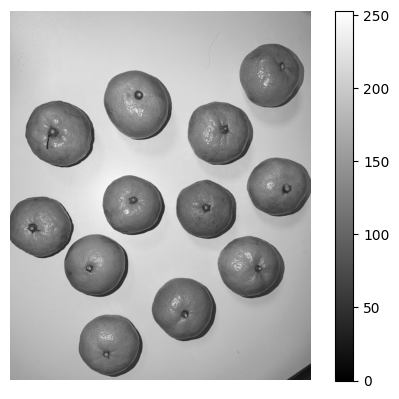

In [115]:
I = Image.open(imgpath).convert('L')
f = np.array(I)
plt.imshow(f,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

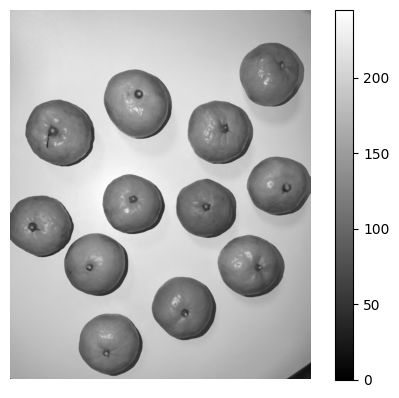

In [116]:
f_denoised = signal.medfilt2d(f,7)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

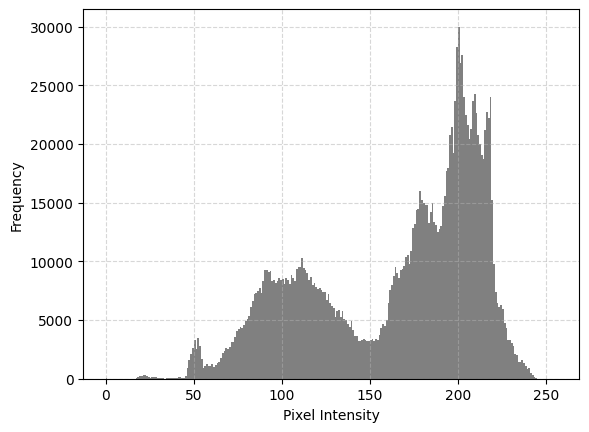

In [117]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

threshold = 149


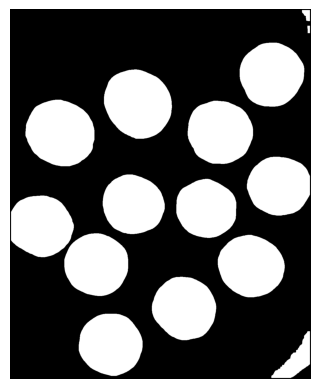

In [118]:

from skimage.filters import threshold_otsu
th_val = threshold_otsu(f_denoised)
print('threshold =', th_val)

f_mask = (f_denoised < th_val) & (f_denoised > 30)


f_mask = nd.binary_closing(f_mask, structure=np.ones((9,9)))
f_mask = nd.binary_fill_holes(f_mask)
f_mask = nd.binary_opening(f_mask, structure=np.ones((9,9)))
plt.imshow(f_mask, cmap='gray'); plt.axis('off'); plt.show()

## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

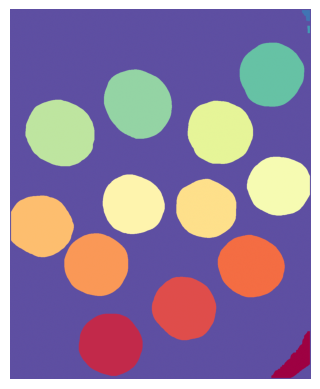

In [119]:
labels, nums = nd.label(f_mask)
plt.imshow(labels,cmap='Spectral_r')
plt.axis('off')
plt.show()

In [120]:
cc = np.zeros((nums, 2))
for i in range(1, nums+1):
    cc[i-1,0] = i
    cc[i-1,1] = np.sum(labels == i)
    print(f'label: {i}, number of pixels: {int(cc[i-1,1])}')

cc = cc[cc[:,1] > 0.5 * np.median(cc[:,1])]
print('object 수:', len(cc))

label: 1, number of pixels: 932
label: 2, number of pixels: 272
label: 3, number of pixels: 48824
label: 4, number of pixels: 54975
label: 5, number of pixels: 54341
label: 6, number of pixels: 49512
label: 7, number of pixels: 44770
label: 8, number of pixels: 43655
label: 9, number of pixels: 42185
label: 10, number of pixels: 46483
label: 11, number of pixels: 47634
label: 12, number of pixels: 48424
label: 13, number of pixels: 47452
label: 14, number of pixels: 46907
label: 15, number of pixels: 11390
object 수: 12


## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [121]:

ind_max = np.argmax(cc[:,1]);  lab_max = cc[ind_max,0]
ind_min = np.argmin(cc[:,1]);  lab_min = cc[ind_min,0]
print(f'the largest : label {int(lab_max)}, # of pixels: {int(cc[ind_max,1])}')
print(f'the smallest: label {int(lab_min)}, # of pixels: {int(cc[ind_min,1])}')


the largest : label 4, # of pixels: 54975
the smallest: label 9, # of pixels: 42185


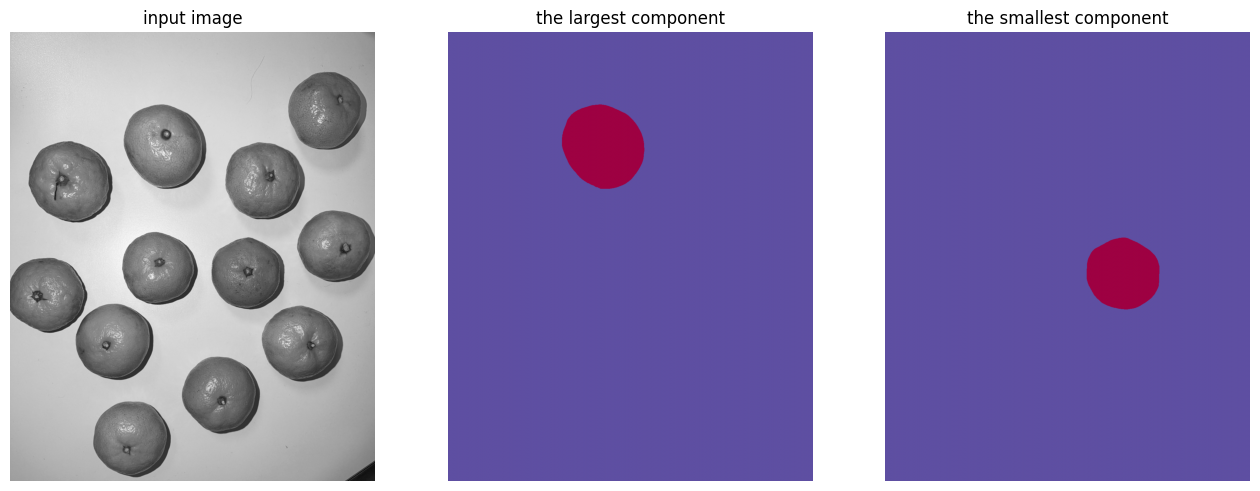

In [122]:
plt.figure(figsize=(16,9))
plt.subplot(131); plt.imshow(f, cmap='gray'); plt.axis('off'); plt.title('input image')
plt.subplot(132); plt.imshow(labels==lab_max, cmap='Spectral_r'); plt.axis('off'); plt.title('the largest component')
plt.subplot(133); plt.imshow(labels==lab_min, cmap='Spectral_r'); plt.axis('off'); plt.title('the smallest component')
plt.show()